## 1. Carregar os dados tratados

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.metrics import f1_score, mean_absolute_error, root_mean_squared_error, make_scorer
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_sample_weight
from IPython.display import display

train = pd.read_parquet("../dados/train_tratado.parquet")

X = train.drop(columns="AGE_RANGE")
y = train["AGE_RANGE"]
print("X:", X.shape)

X: (10962, 287)


In [2]:
# Modelo escolhido na versão anterior (dados antes do mapeamento ordinal); a secção 6 substitui-o
reg_escolhido = HistGradientBoostingRegressor(categorical_features="from_dtype", early_stopping=False,
    random_state=42, min_samples_leaf=50, max_leaf_nodes=31, max_iter=200, max_features=1.0,
    learning_rate=0.1, l2_regularization=0)

## 2. Funções de avaliação

- **Mesmos 5 folds** do classificador (`StratifiedKFold`, `random_state=42`) → resultados comparáveis.
- **Pesos por faixa** (`compute_sample_weight("balanced")`): o equivalente ao `class_weight="balanced"` do classificador.
  Faixas pequenas pesam mais. Sem isto, o regressor puxa as previsões para o meio (faixas 8–10, as mais frequentes).
- Métricas de regressão (PL 2 / PL 4): **MAE** (erro médio em nº de faixas) e **RMSE** (castiga mais os erros grandes).
- **Macro F1** depois de converter o número em faixa (arredondar e limitar a 0–15) — é a métrica do Kaggle.
- Para cada métrica, valor no **treino** e na **validação**: se o treino for muito melhor, há sobreajuste.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pesos = compute_sample_weight("balanced", y)

def arredondar(previsao):
    """Número contínuo -> faixa inteira entre 0 e 15."""
    return np.clip(np.rint(previsao), 0, 15).astype(int)

def f1_arredondado(y_real, previsao):
    return f1_score(y_real, arredondar(previsao), average="macro")

def avaliar_reg(modelo, nome):
    inicio = time.time()
    r = cross_validate(modelo, X, y, cv=cv, scoring="neg_mean_absolute_error",
                       return_estimator=True, return_indices=True, n_jobs=5,
                       params={"sample_weight": pesos})
    oof = np.zeros(len(y))
    linhas = []
    for est, i_tr, i_val in zip(r["estimator"], r["indices"]["train"], r["indices"]["test"]):
        p_tr = est.predict(X.iloc[i_tr])
        p_val = est.predict(X.iloc[i_val])
        oof[i_val] = p_val
        linhas.append({
            "MAE treino": mean_absolute_error(y.iloc[i_tr], p_tr),
            "MAE validação": mean_absolute_error(y.iloc[i_val], p_val),
            "RMSE validação": root_mean_squared_error(y.iloc[i_val], p_val),
            "F1 treino": f1_arredondado(y.iloc[i_tr], p_tr),
            "F1 validação": f1_arredondado(y.iloc[i_val], p_val),
        })
    m = pd.DataFrame(linhas)
    resultado = {"modelo": nome, **m.mean().to_dict(), "desvio F1": m["F1 validação"].std(ddof=0),
                 "segundos": round(time.time() - inicio)}
    print(f"{nome}: F1 validação {resultado['F1 validação']:.4f} ± {resultado['desvio F1']:.4f} | "
          f"F1 treino {resultado['F1 treino']:.4f} | MAE validação {resultado['MAE validação']:.3f} | "
          f"MAE treino {resultado['MAE treino']:.3f}")
    return resultado, oof

resultados = []

## 3. Regressor com parâmetros por defeito

`early_stopping=False` explícito, pela mesma razão do classificador: com `"auto"` o early stopping liga-se só
com mais de 10 000 linhas (treino final) e não nos folds — o modelo validado seria diferente do final.

In [4]:
reg_defeito = HistGradientBoostingRegressor(
    categorical_features="from_dtype",
    early_stopping=False,
    random_state=42,
)
res_defeito, oof_defeito = avaliar_reg(reg_defeito, "regressor defeito")
resultados.append(res_defeito)

regressor defeito: F1 validação 0.4334 ± 0.0080 | F1 treino 0.5742 | MAE validação 0.753 | MAE treino 0.559


## 4. Converter o número numa faixa

**Arredondar** usa cortes fixos em 0,5 / 1,5 / ... / 14,5. Mas o regressor tende a encolher as previsões para o meio
(nas faixas extremas raramente prevê 0 ou 15), por isso os cortes fixos não são os melhores para o Macro F1.

**Cortes otimizados:** procuramos os 15 cortes que maximizam o Macro F1 (descida por coordenadas: ajusta um corte
de cada vez, mantendo os outros, e repete).

**Atenção ao data leakage:** se otimizássemos os cortes nas mesmas previsões em que medimos o F1, o resultado seria
otimista. Por isso, para cada fold, os cortes são aprendidos nas previsões *out-of-fold* dos **outros 4 folds**
e aplicados ao fold que ficou de fora.

In [5]:
def otimizar_cortes(previsao, y_real, passagens=3):
    cortes = np.arange(0.5, 15, 1.0)                       # começa no arredondamento
    melhor = f1_score(y_real, np.digitize(previsao, cortes), average="macro")
    for _ in range(passagens):
        for k in range(len(cortes)):
            baixo = cortes[k - 1] if k > 0 else previsao.min()
            cima = cortes[k + 1] if k < len(cortes) - 1 else previsao.max()
            for valor in np.linspace(baixo, cima, 21)[1:-1]:
                tentativa = cortes.copy()
                tentativa[k] = valor
                f = f1_score(y_real, np.digitize(previsao, tentativa), average="macro")
                if f > melhor:
                    melhor, cortes = f, tentativa
    return cortes

def f1_com_cortes(oof):
    """F1 de validação com cortes aprendidos fora de cada fold (sem leakage)."""
    f1s = []
    for i_tr, i_val in cv.split(X, y):
        cortes = otimizar_cortes(oof[i_tr], y.iloc[i_tr].values)
        f1s.append(f1_score(y.iloc[i_val], np.digitize(oof[i_val], cortes), average="macro"))
    return np.mean(f1s), np.std(f1s)

f1_c, desvio_c = f1_com_cortes(oof_defeito)
print(f"Arredondar:         F1 {res_defeito['F1 validação']:.4f}")
print(f"Cortes otimizados:  F1 {f1_c:.4f} ± {desvio_c:.4f}")

Arredondar:         F1 0.4334
Cortes otimizados:  F1 0.4517 ± 0.0070


In [6]:
# Os cortes aprendidos com todas as previsões out-of-fold (só para ver como ficam)
cortes_defeito = otimizar_cortes(oof_defeito, y.values)
pd.DataFrame({"arredondar": np.arange(0.5, 15, 1.0), "otimizado": cortes_defeito.round(2)},
             index=[f"{k}|{k+1}" for k in range(15)]).T

,0|1,1|2,2|3,3|4,4|5,5|6,6|7,7|8,8|9,9|10,10|11,11|12,12|13,13|14,14|15
arredondar,0.50,1.50,2.50,3.50,4.5,5.50,6.50,7.50,8.50,9.5,10.50,11.50,12.5,13.50,14.50
otimizado,0.69,1.44,2.88,3.85,4.6,5.35,6.32,7.08,8.77,9.6,10.55,11.98,12.6,13.35,14.16


## 5. Procura de hiperparâmetros para o objetivo real (F1 com cortes otimizados)

Na versão anterior a procura escolhia pelo **F1 com arredondamento**, e os cortes otimizados só eram aplicados depois.
Mas o regressor vai ser usado **com cortes**, e os cortes corrigem parte do "encolhimento para o meio". Uma combinação
que arredonda mal pode ficar ótima depois dos cortes. Por isso agora **cada combinação é avaliada já com cortes**:

1. previsões *out-of-fold* da combinação (mesmos 5 folds, pesos balanceados);
2. F1 de validação com cortes aprendidos nos **outros 4 folds** (`f1_com_cortes`, sem leakage);
3. F1 de treino com cortes aprendidos nas previsões de treino desse fold (para medir o sobreajuste da mesma forma).

A grelha é a mesma de antes mais a **função de perda** (`loss`):
- `squared_error`: castiga mais os erros grandes (puxa para a média);
- `absolute_error`: castiga todos os erros por igual (puxa para a mediana, menos sensível a pessoas "estranhas").

30 combinações. O `RandomizedSearchCV` não serve aqui porque o critério precisa das previsões de todos os folds juntas
(os cortes de um fold vêm dos outros), por isso o ciclo é feito à mão com `ParameterSampler`
(sorteia as combinações da mesma forma que o `RandomizedSearchCV`). Demora cerca de 30 minutos.

In [7]:
import warnings
from sklearn.model_selection import ParameterSampler

def avaliar_com_cortes(modelo):
    r = cross_validate(modelo, X, y, cv=cv, scoring="neg_mean_absolute_error",
                       return_estimator=True, return_indices=True, n_jobs=5,
                       params={"sample_weight": pesos})
    oof = np.zeros(len(y))
    f1_tr, mae_tr = [], []
    for est, i_tr, i_val in zip(r["estimator"], r["indices"]["train"], r["indices"]["test"]):
        p_tr = est.predict(X.iloc[i_tr])
        oof[i_val] = est.predict(X.iloc[i_val])
        cortes_tr = otimizar_cortes(p_tr, y.iloc[i_tr].values)
        f1_tr.append(f1_score(y.iloc[i_tr], np.digitize(p_tr, cortes_tr), average="macro"))
        mae_tr.append(mean_absolute_error(y.iloc[i_tr], p_tr))
    f1_val, desvio = f1_com_cortes(oof)
    return {"F1 treino": np.mean(f1_tr), "F1 validação": f1_val, "desvio": desvio,
            "F1 arredondado": f1_arredondado(y, oof),
            "MAE treino": np.mean(mae_tr), "MAE validação": mean_absolute_error(y, oof)}, oof

reg_base = HistGradientBoostingRegressor(categorical_features="from_dtype", early_stopping=False, random_state=42)

grelha = {
    "loss": ["squared_error", "absolute_error"],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_iter": [200, 400, 800],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [10, 20, 50, 100],
    "l2_regularization": [0, 1, 5],
    "max_features": [0.5, 0.7, 1.0],
}
combinacoes = list(ParameterSampler(grelha, n_iter=30, random_state=42))

linhas, oofs = [], []
inicio = time.time()
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*does not support sample_weight.*")
    for j, params in enumerate(combinacoes):
        res, oof = avaliar_com_cortes(HistGradientBoostingRegressor(**{**reg_base.get_params(), **params}))
        linhas.append({**params, **res})
        oofs.append(oof)
        print(f"{j + 1:2d}/30  F1 validação (cortes) {res['F1 validação']:.4f} | treino {res['F1 treino']:.4f} | "
              f"{(time.time() - inicio) / 60:.1f} min", flush=True)

tabela = pd.DataFrame(linhas)
tabela["diferença F1"] = tabela["F1 treino"] - tabela["F1 validação"]
print(f"Melhor F1 validação (cortes): {tabela['F1 validação'].max():.4f}  vs  defeito com cortes {f1_c:.4f}")

 1/30  F1 validação (cortes) 0.4459 | treino 0.6752 | 9.4 min


 2/30  F1 validação (cortes) 0.4571 | treino 0.9258 | 26.7 min


 3/30  F1 validação (cortes) 0.4551 | treino 0.5896 | 32.0 min


 4/30  F1 validação (cortes) 0.4613 | treino 0.6676 | 33.9 min


 5/30  F1 validação (cortes) 0.4643 | treino 0.7047 | 37.9 min


 6/30  F1 validação (cortes) 0.4429 | treino 0.5750 | 40.4 min


... (21 outputs left out)

28/30  F1 validação (cortes) 0.4497 | treino 0.5952 | 96.8 min


29/30  F1 validação (cortes) 0.4563 | treino 0.7740 | 113.4 min


30/30  F1 validação (cortes) 0.4720 | treino 0.8090 | 118.8 min


Melhor F1 validação (cortes): 0.4720  vs  defeito com cortes 0.4517


In [8]:
tabela.sort_values("F1 validação", ascending=False).round(4)

,min_samples_leaf,max_leaf_nodes,max_iter,max_features,loss,learning_rate,l2_regularization,F1 treino,F1 validação,desvio,F1 arredondado,MAE treino,MAE validação,diferença F1
29,10,63,400,0.7,squared_error,0.03,0,0.8090,0.4720,0.0108,0.4539,0.3669,0.7248,0.3370
16,20,63,800,0.7,squared_error,0.03,0,0.9454,0.4698,0.0053,0.4531,0.2217,0.7177,0.4756
4,100,31,400,1.0,squared_error,0.05,0,0.7047,0.4643,0.0124,0.4414,0.4617,0.7391,0.2404
3,50,63,200,1.0,absolute_error,0.05,1,0.6676,0.4613,0.0028,0.4543,0.4990,0.7394,0.2064
24,10,31,400,1.0,squared_error,0.03,1,0.6464,0.4609,0.0089,0.4392,0.5267,0.7437,0.1856
17,10,63,400,1.0,squared_error,0.05,5,0.8991,0.4608,0.0104,0.4447,0.2737,0.7278,0.4383
7,50,63,400,0.7,absolute_error,0.10,0,0.7460,0.4589,0.0084,0.4510,0.4043,0.7392,0.2871
9,20,31,400,1.0,squared_error,0.05,0,0.7368,0.4575,0.0073,0.4428,0.4314,0.7368,0.2793
22,20,63,200,1.0,absolute_error,0.05,1,0.6742,0.4575,0.0083,0.4531,0.5006,0.7388,0.2167
1,50,63,800,1.0,squared_error,0.03,5,0.9258,0.4571,0.0053,0.4428,0.2477,0.7294,0.4687


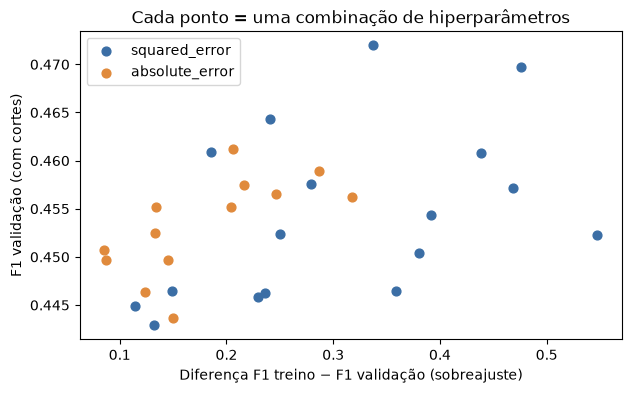

Melhor F1 de validação por função de perda:
{'absolute_error': 0.4613, 'squared_error': 0.472}


In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for perda, cor in [("squared_error", "#3b6ea5"), ("absolute_error", "#e08a3c")]:
    t = tabela[tabela["loss"] == perda]
    ax.scatter(t["diferença F1"], t["F1 validação"], color=cor, s=40, label=perda)
ax.set_xlabel("Diferença F1 treino − F1 validação (sobreajuste)")
ax.set_ylabel("F1 validação (com cortes)")
ax.set_title("Cada ponto = uma combinação de hiperparâmetros")
ax.legend()
plt.show()

print("Melhor F1 de validação por função de perda:")
print(tabela.groupby("loss")["F1 validação"].max().round(4).to_dict())

## 6. Escolher o modelo e avaliar

**Regra do "um desvio padrão"** (agora sobre o F1 com cortes): entre as combinações cujo F1 de validação está dentro de
um desvio padrão da melhor, escolhe-se a que tem **menor diferença treino−validação**. Generaliza igual (a diferença
para a melhor é do tamanho do ruído entre folds) mas sobreajusta menos.

Se nenhuma combinação da procura bater o regressor por defeito com cortes, fica o por defeito.

In [10]:
i_melhor = tabela["F1 validação"].idxmax()
limite = tabela.loc[i_melhor, "F1 validação"] - tabela.loc[i_melhor, "desvio"]
candidatos = tabela[tabela["F1 validação"] >= limite].sort_values("diferença F1")
print(f"Melhor F1 validação: {tabela.loc[i_melhor, 'F1 validação']:.4f} | limite (melhor − 1 desvio): {limite:.4f}")
print(f"{len(candidatos)} combinações dentro do limite:")
display(candidatos.round(4))

i_escolhido = candidatos.index[0]
if tabela.loc[i_escolhido, "F1 validação"] > f1_c:
    params_escolhidos = combinacoes[i_escolhido]
    reg_escolhido = HistGradientBoostingRegressor(**{**reg_base.get_params(), **params_escolhidos})
    oof_escolhido = oofs[i_escolhido]
    nome = "regressor escolhido (regra 1 desvio) + cortes"
else:
    params_escolhidos, reg_escolhido, oof_escolhido, nome = {}, reg_defeito, oof_defeito, "regressor defeito + cortes"
print("Escolhido:", nome, params_escolhidos)

colunas = ["F1 treino", "F1 validação", "desvio", "diferença F1", "MAE validação"]
resumo = pd.DataFrame([
    {"modelo": "regressor defeito (arredondar)", "F1 treino": res_defeito["F1 treino"],
     "F1 validação": res_defeito["F1 validação"], "desvio": res_defeito["desvio F1"],
     "MAE validação": res_defeito["MAE validação"]},
    {"modelo": "regressor defeito + cortes", "F1 validação": f1_c, "desvio": desvio_c},
    {"modelo": "melhor da procura + cortes (sem a regra)", **tabela.loc[i_melhor, colunas]},
    {"modelo": nome, **tabela.loc[i_escolhido, colunas]},
]).set_index("modelo")
resumo.loc["classificador HGB (procura 2), para comparar", "F1 validação"] = 0.5891
resumo.round(4)

Melhor F1 validação: 0.4720 | limite (melhor − 1 desvio): 0.4612
4 combinações dentro do limite:


,min_samples_leaf,max_leaf_nodes,max_iter,max_features,loss,learning_rate,l2_regularization,F1 treino,F1 validação,desvio,F1 arredondado,MAE treino,MAE validação,diferença F1
3,50,63,200,1.0,absolute_error,0.05,1,0.6676,0.4613,0.0028,0.4543,0.4990,0.7394,0.2064
4,100,31,400,1.0,squared_error,0.05,0,0.7047,0.4643,0.0124,0.4414,0.4617,0.7391,0.2404
29,10,63,400,0.7,squared_error,0.03,0,0.8090,0.4720,0.0108,0.4539,0.3669,0.7248,0.3370
16,20,63,800,0.7,squared_error,0.03,0,0.9454,0.4698,0.0053,0.4531,0.2217,0.7177,0.4756


Escolhido: regressor escolhido (regra 1 desvio) + cortes {'min_samples_leaf': 50, 'max_leaf_nodes': 63, 'max_iter': 200, 'max_features': 1.0, 'loss': 'absolute_error', 'learning_rate': 0.05, 'l2_regularization': 1}


,F1 treino,F1 validação,desvio,MAE validação,diferença F1
modelo,,,,,
regressor defeito (arredondar),0.5742,0.4334,0.0080,0.7528,NaN
regressor defeito + cortes,NaN,0.4517,0.0070,NaN,NaN
melhor da procura + cortes (sem a regra),0.8090,0.4720,0.0108,0.7248,0.3370
regressor escolhido (regra 1 desvio) + cortes,0.6676,0.4613,0.0028,0.7394,0.2064
"classificador HGB (procura 2), para comparar",NaN,0.5891,NaN,NaN,NaN


## 7. Onde o regressor erra

As previsões finais usam os cortes otimizados, aprendidos fora de cada fold.

In [11]:
faixa_oof = np.zeros(len(y), dtype=int)
for i_tr, i_val in cv.split(X, y):
    cortes = otimizar_cortes(oof_escolhido[i_tr], y.iloc[i_tr].values)
    faixa_oof[i_val] = np.digitize(oof_escolhido[i_val], cortes)

print(classification_report(y, faixa_oof, digits=3))

              precision    recall  f1-score   support

           0      0.798     0.932     0.860       207
           1      0.504     0.413     0.454       172
           2      0.593     0.519     0.553       399
           3      0.368     0.313     0.338       377
           4      0.280     0.330     0.303       449
           5      0.329     0.346     0.337       647
           6      0.333     0.389     0.359       859
           7      0.372     0.393     0.382       862
           8      0.692     0.538     0.605       905
           9      0.653     0.639     0.646      1014
          10      0.577     0.633     0.604      1062
          11      0.528     0.455     0.489      1040
          12      0.383     0.433     0.407      1000
          13      0.308     0.386     0.343       823
          14      0.352     0.323     0.337       650
          15      0.555     0.304     0.393       496

    accuracy                          0.458     10962
   macro avg      0.477   

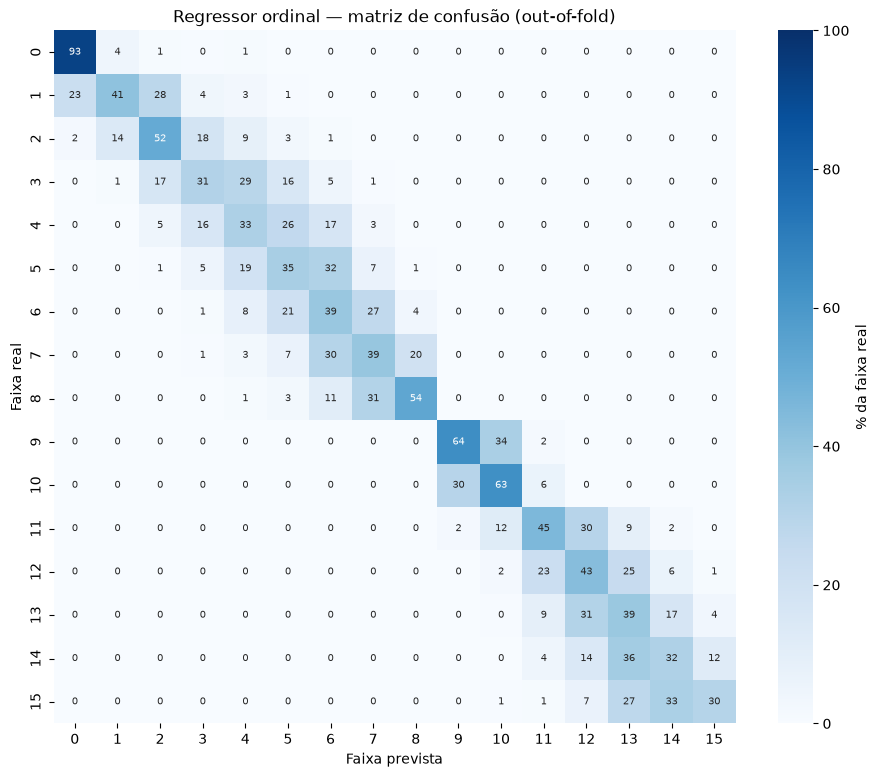

Distância dos erros (% das pessoas):
0    45.8
1    41.6
2    10.2
3     1.9
4     0.3
5     0.1
6     0.0
Name: proportion, dtype: float64


In [12]:
matriz = confusion_matrix(y, faixa_oof, normalize="true") * 100
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(matriz, cmap="Blues", vmin=0, vmax=100, annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "% da faixa real"}, ax=ax)
ax.set_xlabel("Faixa prevista")
ax.set_ylabel("Faixa real")
ax.set_title("Regressor ordinal — matriz de confusão (out-of-fold)")
plt.show()

distancia = np.abs(faixa_oof - y.values)
print("Distância dos erros (% das pessoas):")
print((pd.Series(distancia).value_counts(normalize=True).sort_index() * 100).round(1).head(8))

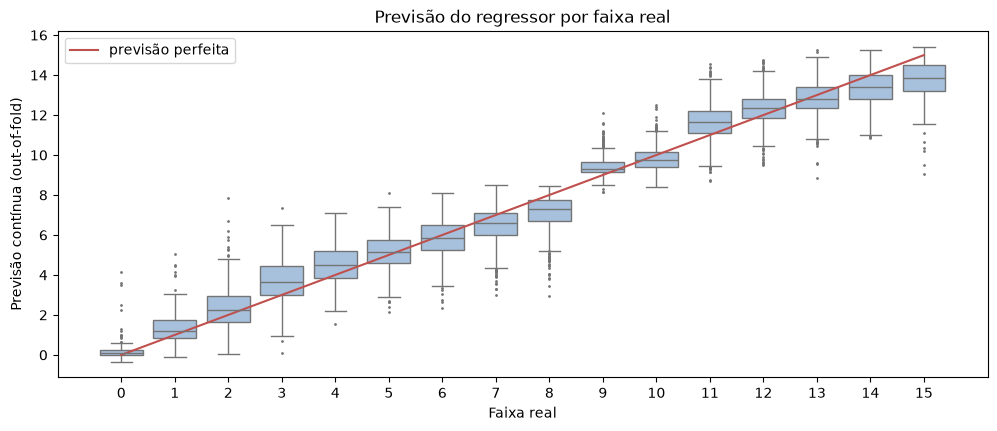

Erro médio (previsto − real) por faixa: + = prevê mais velho, − = prevê mais novo
{0: 0.23, 1: 0.35, 2: 0.42, 3: 0.73, 4: 0.49, 5: 0.11, 6: -0.19, 7: -0.52, 8: -0.86, 9: 0.42, 10: -0.17, 11: 0.6, 12: 0.34, 13: -0.17, 14: -0.63, 15: -1.21}


In [13]:
# Previsão contínua por faixa real: mostra o "encolhimento para o meio"
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(x=y, y=oof_escolhido, color="#9ec1e6", fliersize=1, ax=ax)
ax.plot(range(16), range(16), color="#c0504d", lw=1.5, label="previsão perfeita")
ax.set_xlabel("Faixa real")
ax.set_ylabel("Previsão contínua (out-of-fold)")
ax.set_title("Previsão do regressor por faixa real")
ax.legend()
plt.show()

vies = pd.Series(oof_escolhido - y.values).groupby(y.values).mean().round(2)
print("Erro médio (previsto − real) por faixa: + = prevê mais velho, − = prevê mais novo")
print(vies.to_dict())

## 8. Gráficos de sobreajuste

Dois gráficos clássicos para diagnosticar sobreajuste:

**a) Curva por iteração** — o modelo é treinado com mais iterações do que o escolhido e, a cada iteração,
medimos o desempenho no treino e na validação (`staged_predict`: previsões do modelo "parcial" após 1, 2, ... iterações).
- Treino a subir sempre e validação a estabilizar → a partir daí as iterações extra só decoram o treino.
- MAE de validação a **subir** enquanto a de treino desce → sobreajuste clássico.
- A linha vertical marca o nº de iterações escolhido.

**b) Curva de aprendizagem** — o modelo é treinado com 20%, 40%, ..., 100% dos dados de treino de cada fold.
- **Diferença grande** entre treino e validação → variância alta (sobreajuste): ajudam regularização, menos colunas, ensembles.
- **Validação ainda a subir** no fim → mais dados ajudariam (aqui não há mais, mas mostra que o modelo está limitado pelos dados).
- **As duas curvas baixas e juntas** → subajuste: o modelo é demasiado simples ou faltam features.

Cada curva mostra a média dos 5 folds (linha) e ± 1 desvio padrão (sombra). Demora alguns minutos.

### a) Curva por iteração

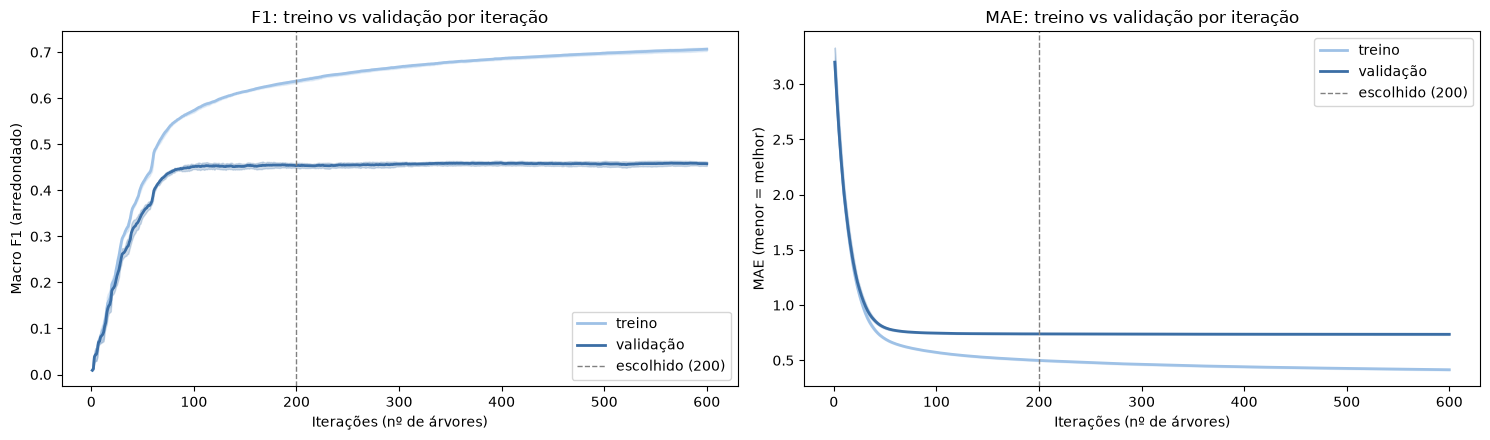

F1 validação: máximo 0.4594 na iteração 399 | na iteração escolhida 0.4538
MAE validação: mínimo 0.7356 na iteração 594 | na iteração escolhida 0.7394


In [14]:
from joblib import Parallel, delayed

MAX_ITER_CURVA = 600
params_curva = {**reg_escolhido.get_params(), "max_iter": MAX_ITER_CURVA}

def curva_fold(i_tr, i_val):
    m = HistGradientBoostingRegressor(**params_curva).fit(X.iloc[i_tr], y.iloc[i_tr], sample_weight=pesos[i_tr])
    out = {}
    for nome, idx in [("treino", i_tr), ("validação", i_val)]:
        yy = y.iloc[idx]
        previsoes = list(m.staged_predict(X.iloc[idx]))
        out[f"F1 {nome}"] = [f1_arredondado(yy, p) for p in previsoes]
        out[f"MAE {nome}"] = [mean_absolute_error(yy, p) for p in previsoes]
    return out

folds = Parallel(n_jobs=5)(delayed(curva_fold)(i_tr, i_val) for i_tr, i_val in cv.split(X, y))
curvas = {k: np.array([f[k] for f in folds]) for k in folds[0]}
iteracoes = np.arange(1, MAX_ITER_CURVA + 1)
n_escolhido = reg_escolhido.get_params()["max_iter"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, metrica in zip(axes, ["F1", "MAE"]):
    for nome, cor in [("treino", "#9ec1e6"), ("validação", "#3b6ea5")]:
        v = curvas[f"{metrica} {nome}"]
        ax.plot(iteracoes, v.mean(0), color=cor, lw=2, label=nome)
        ax.fill_between(iteracoes, v.mean(0) - v.std(0), v.mean(0) + v.std(0), color=cor, alpha=0.25)
    ax.axvline(n_escolhido, color="grey", ls="--", lw=1, label=f"escolhido ({n_escolhido})")
    ax.set_xlabel("Iterações (nº de árvores)")
    ax.set_ylabel("Macro F1 (arredondado)" if metrica == "F1" else "MAE (menor = melhor)")
    ax.set_title(f"{metrica}: treino vs validação por iteração")
    ax.legend()
plt.tight_layout()
plt.show()

v_f1 = curvas["F1 validação"].mean(0)
v_mae = curvas["MAE validação"].mean(0)
print(f"F1 validação: máximo {v_f1.max():.4f} na iteração {v_f1.argmax() + 1} | na iteração escolhida {v_f1[n_escolhido - 1]:.4f}")
print(f"MAE validação: mínimo {v_mae.min():.4f} na iteração {v_mae.argmin() + 1} | na iteração escolhida {v_mae[n_escolhido - 1]:.4f}")

### b) Curva de aprendizagem

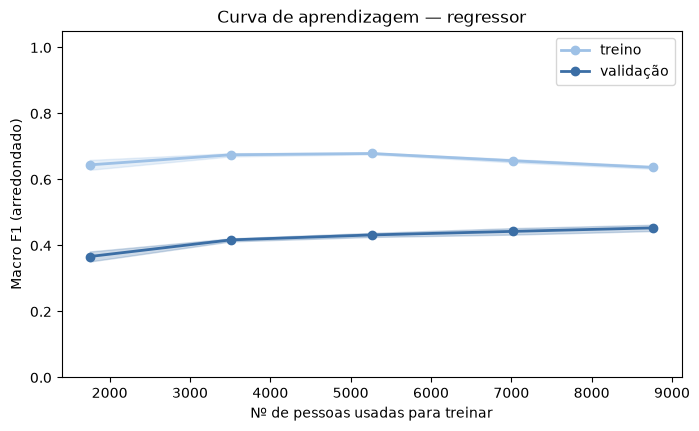

,pessoas no treino,F1 treino,F1 validação,diferença
0,1753,0.6443,0.3666,0.2777
1,3507,0.6749,0.4170,0.2579
2,5261,0.6788,0.4320,0.2468
3,7015,0.6569,0.4428,0.2141
4,8769,0.6367,0.4534,0.1833


In [15]:
from sklearn.model_selection import learning_curve

fracoes = [0.2, 0.4, 0.6, 0.8, 1.0]
tamanhos, f1_tr, f1_val = learning_curve(
    reg_escolhido, X, y, cv=cv, train_sizes=fracoes, scoring=make_scorer(f1_arredondado),
    n_jobs=-1, shuffle=True, random_state=42, params={"sample_weight": pesos},
)

fig, ax = plt.subplots(figsize=(8, 4.5))
for valores, nome, cor in [(f1_tr, "treino", "#9ec1e6"), (f1_val, "validação", "#3b6ea5")]:
    ax.plot(tamanhos, valores.mean(1), "o-", color=cor, lw=2, label=nome)
    ax.fill_between(tamanhos, valores.mean(1) - valores.std(1), valores.mean(1) + valores.std(1), color=cor, alpha=0.25)
ax.set_xlabel("Nº de pessoas usadas para treinar")
ax.set_ylabel("Macro F1 (arredondado)")
ax.set_ylim(0, 1.05)
ax.set_title("Curva de aprendizagem — regressor")
ax.legend()
plt.show()

pd.DataFrame({"pessoas no treino": tamanhos, "F1 treino": f1_tr.mean(1), "F1 validação": f1_val.mean(1),
              "diferença": f1_tr.mean(1) - f1_val.mean(1)}).round(4)

## 9. Preparar para o ensemble (stacking)

No stacking, um modelo final aprende a combinar as saídas do HGB, do Random Forest e deste regressor.
Para isso cada modelo tem de fornecer:

1. **Previsões *out-of-fold* do treino** — cada pessoa prevista pelo modelo que **não** a viu no treino.
   É com estas que o modelo final aprende. Se usássemos previsões do modelo treinado com todos os dados, ele
   já teria visto as respostas (F1 de treino perto de 1) e o modelo final aprenderia a confiar nele demais.
2. **Os mesmos 5 folds em todos os modelos** (`StratifiedKFold`, `random_state=42`, igual ao `02.1_random_forest.py`):
   assim, quando o modelo final for validado, nenhuma pessoa de validação foi vista por nenhum dos três.
3. **Previsões do teste** feitas pelo modelo treinado com **todos** os dados de treino.

O regressor entra com a **previsão contínua** (ex: 7,3), não com a faixa depois dos cortes: o número tem mais
informação (7,3 e 7,9 são diferentes) e o modelo final aprende sozinho como o usar.

Esta secção é **independente** das anteriores (carrega os dados e define o modelo de novo), para poder ser corrida
sozinha. Os hiperparâmetros são os escolhidos na secção 6 (regra do um desvio padrão, F1 com cortes 0,4751).

In [16]:
import os
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, mean_absolute_error
from sklearn.utils.class_weight import compute_sample_weight

train = pd.read_parquet("../dados/train_tratado.parquet")
test = pd.read_parquet("../dados/test_tratado.parquet")
X = train.drop(columns="AGE_RANGE")
y = train["AGE_RANGE"]
X_test = test[X.columns]
pesos = compute_sample_weight("balanced", y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

PARAMS_ESCOLHIDOS = {"loss": "squared_error", "learning_rate": 0.03, "max_iter": 400, "max_leaf_nodes": 63,
                     "min_samples_leaf": 10, "max_features": 0.7, "l2_regularization": 0}   # secção 6

def criar_regressor():
    return HistGradientBoostingRegressor(categorical_features="from_dtype", early_stopping=False,
                                         random_state=42, **PARAMS_ESCOLHIDOS)

# Previsões out-of-fold (cada fold treinado com pesos balanceados, como na avaliação)
oof = cross_val_predict(criar_regressor(), X, y, cv=cv, params={"sample_weight": pesos}, n_jobs=5)

# Verificação: devem coincidir com a secção 6 (F1 arredondado 0,4566 | MAE validação 0,714)
faixa = np.clip(np.rint(oof), 0, 15).astype(int)
print(f"OOF: F1 arredondado {f1_score(y, faixa, average='macro'):.4f} | MAE {mean_absolute_error(y, oof):.3f}")

OOF: F1 arredondado 0.4539 | MAE 0.725


In [17]:
# Modelo final: treinado com todos os dados de treino -> previsões do teste
final = criar_regressor().fit(X, y, sample_weight=pesos)
previsao_teste = final.predict(X_test)

os.makedirs("../resultados", exist_ok=True)      # previsões ligadas aos dados: não vão para o GitHub
pid = pd.read_csv("../dados/dataset_train.csv", usecols=["PID"])["PID"].values
pd.DataFrame({"PID": pid, "real": y.values, "reg_continua": oof}).to_csv("../resultados/oof_regressor.csv", index=False)
pd.DataFrame({"RowId": np.arange(len(X_test)), "reg_continua": previsao_teste}).to_csv(
    "../resultados/test_regressor.csv", index=False)

assert len(previsao_teste) == 3655
print("Gravados: ../resultados/oof_regressor.csv e ../resultados/test_regressor.csv")
print("Previsão contínua — treino (OOF):", pd.Series(oof).describe()[["mean", "min", "max"]].round(2).to_dict())
print("Previsão contínua — teste:       ", pd.Series(previsao_teste).describe()[["mean", "min", "max"]].round(2).to_dict())

Gravados: ../resultados/oof_regressor.csv e ../resultados/test_regressor.csv
Previsão contínua — treino (OOF): {'mean': 8.75, 'min': -0.12, 'max': 15.23}
Previsão contínua — teste:        {'mean': 8.75, 'min': 0.03, 'max': 15.28}
